# 04 — Summary

Loads all cached results (`outputs/meeting_2026-10-14`); no training.

**Setup.** Nektar cylinder wake (Raissi PINN data), 200 snapshots × 5000 grid points (100 × 50, x∈[1,8], y∈[−2,2]).
Target: both velocity components, state = [u; v] (10 000 values). N = 8 probes, each reading u and v at one grid point,
placed by block-QR pivoting over grid points on the rank-16 POD basis of the training data. Lags = 10, interleaved
80/10/10 window split, seeds {0, 1, 2} (seed changes split, probe locations, POD basis and init). GRU for all recurrent models.

**Corruption (identical for all methods).** Gaussian noise σ = 0.05 × per-channel training std, added in unscaled
units (fresh per batch in training; fixed seeded realisation at test). Dropout: each probe fails with probability p for
the whole lag window (both channels), at least one probe survives. Training p = 0.3 for "-dropout" and masked models.
Test: p = 0 and p = 0.3, 10 fixed draws per test window, shared across methods (and gappy POD).
Zero-fill methods see 0 in the min-max scaled input space (= training minimum of that probe, not "no signal").
Masked methods (SenseiverSDN, RobustSHREDv1/v2) exclude failed probes from attention (key padding mask + learned null
token); gappy POD solves least squares with the available rows, rank r' = min(16, 2·available), clipped to the
training range. Early stopping uses a validation set corrupted like the method's training data.

In [1]:
RUN_TRAINING = False   # True: train runs that are not cached yet (cached runs are skipped)
QUICK = False          # True: 1 seed, 20 epochs, separate cache dir (smoke test)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from get_shredded import meeting_plots as mp
from get_shredded.meeting_runner import (
    LATENT_METHODS, load_arrays, load_config, load_results, load_seed_info, prepare_seed, run_all,
)

TIER_A = ["SHRED-noise", "SHRED-dropout", "SDN-noise", "SDN-dropout",
          "SenseiverSDN", "RobustSHREDv1", "RobustSHREDv2", "GappyPOD"]
TIER_B = ["SHRED-dropout+mask"]
METHODS = TIER_A + TIER_B
OVERRIDES = ["meeting.methods=[" + ",".join(METHODS) + "]"]
if QUICK:
    OVERRIDES += ["meeting.seeds=[0]", "train.epochs=20", "outputs.root=outputs/meeting_2026-10-14_quick"]
cfg = load_config(OVERRIDES)
ROOT = cfg.outputs.root
if RUN_TRAINING:
    run_all(cfg)
results = load_results(ROOT)
print(f"{len(results)} completed runs in {ROOT}")

27 completed runs in outputs/meeting_2026-10-14


## Summary table

In [2]:
display(Markdown(mp.summary_table(results, METHODS)))

| Method | Params | Seeds | Clean | p = 0 | p = 0.3 | p = 0.3 (u) | p = 0.3 (v) |
|---|---:|---:|---:|---:|---:|---:|---:|
| SHRED-noise | 4,213,854 | 3 | 0.0040 ± 0.0006 | 0.0047 ± 0.0006 | 0.1589 ± 0.0062 | 0.0832 ± 0.0041 | 0.4734 ± 0.0174 |
| SHRED-dropout | 4,213,854 | 3 | 0.0102 ± 0.0027 | 0.0108 ± 0.0025 | 0.0145 ± 0.0035 | 0.0076 ± 0.0018 | 0.0433 ± 0.0106 |
| SDN-noise | 4,156,350 | 3 | 0.0040 ± 0.0004 | 0.0071 ± 0.0006 | 0.1803 ± 0.0061 | 0.0928 ± 0.0040 | 0.5401 ± 0.0174 |
| SDN-dropout | 4,156,350 | 3 | 0.0101 ± 0.0012 | 0.0127 ± 0.0014 | 0.0243 ± 0.0017 | 0.0125 ± 0.0008 | 0.0728 ± 0.0054 |
| SenseiverSDN | 4,253,502 | 3 | 0.0152 ± 0.0017 | 0.0169 ± 0.0017 | 0.0283 ± 0.0046 | 0.0147 ± 0.0024 | 0.0846 ± 0.0138 |
| RobustSHREDv1 | 4,224,382 | 3 | 0.0108 ± 0.0015 | 0.0115 ± 0.0014 | 0.0150 ± 0.0011 | 0.0078 ± 0.0005 | 0.0449 ± 0.0034 |
| RobustSHREDv2 | 4,273,086 | 3 | 0.0094 ± 0.0009 | 0.0103 ± 0.0012 | 0.0151 ± 0.0019 | 0.0078 ± 0.0009 | 0.0451 ± 0.0056 |
| GappyPOD | – | 3 | 0.0007 ± 0.0000 | 0.0139 ± 0.0003 | 0.0916 ± 0.0089 | 0.0562 ± 0.0047 | 0.2551 ± 0.0269 |
| SHRED-dropout+mask | 4,215,390 | 3 | 0.0099 ± 0.0013 | 0.0102 ± 0.0013 | 0.0113 ± 0.0018 | 0.0059 ± 0.0009 | 0.0337 ± 0.0052 |

**Takeaway:** Under p = 0.3 dropout, every model trained on the same corruption (zero-fill or masked) beats gappy POD by 3–8×, and the noise-only models fail. The three recurrent dropout-trained models (SHRED-dropout, RobustSHREDv1, RobustSHREDv2) are tied at ≈ 0.015; SHRED with missing flags is lowest (0.011); the non-recurrent SDN-dropout and SenseiverSDN are worse (0.024, 0.028).

## Headline figures

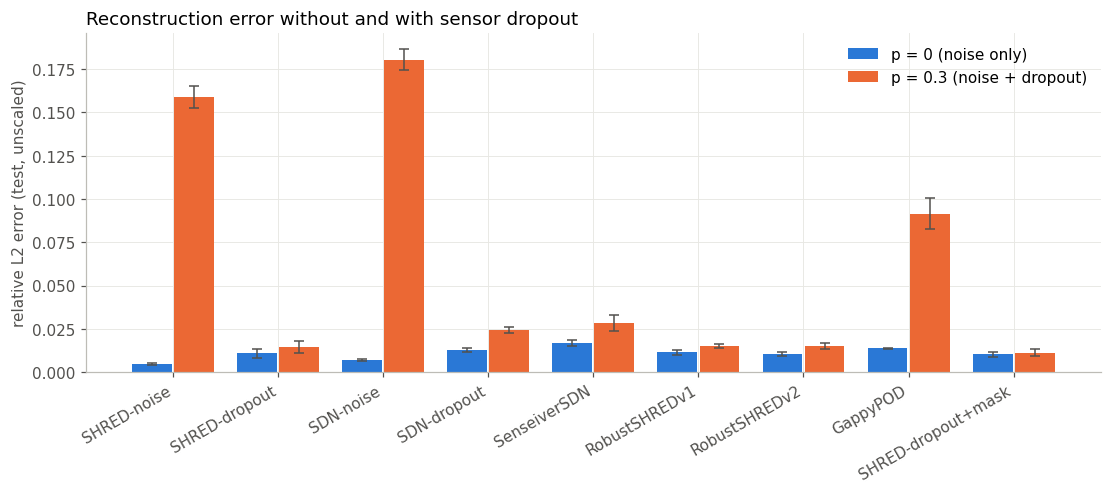

In [3]:
fig = mp.plot_error_bars(results, METHODS).figure; plt.show()

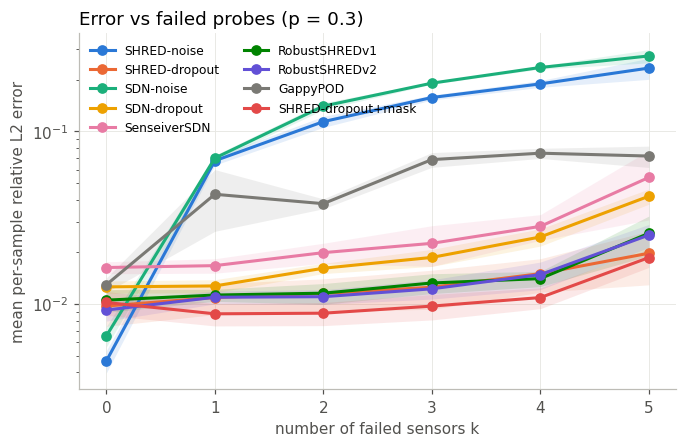

In [4]:
fig = mp.plot_by_k(ROOT, results, METHODS, "p0.3_err", "mean per-sample relative L2 error", "Error vs failed probes (p = 0.3)", logy=True).figure; plt.show()

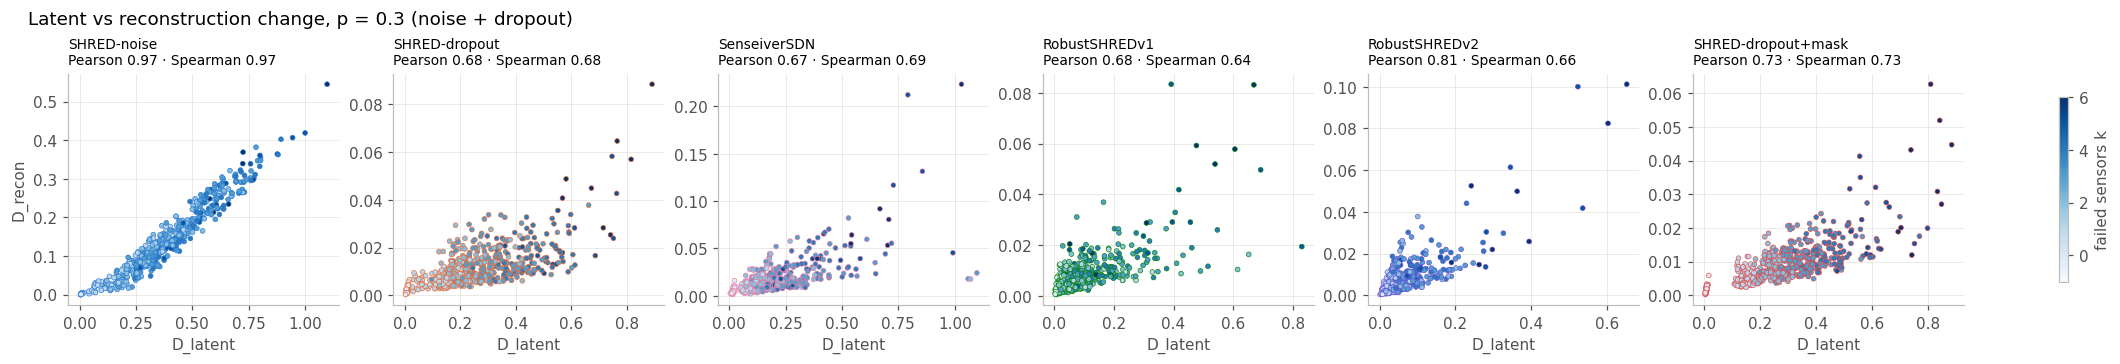

In [5]:
fig = mp.plot_latent_scatter(ROOT, results, [m for m in METHODS if m in LATENT_METHODS], "p0.3"); plt.show()

**Takeaway:** Headlines: (1) training on the corruption matters far more than architecture; (2) given the same training corruption, set-based attention with masking does not beat zero-filled SHRED on this dataset; (3) the attention-based recurrent models have the most invariant latents, but this does not translate into lower error.

## Automated checks

In [6]:
from get_shredded.meeting_runner import masked_invariance_check
issues = []
pod = mp.metric_over_seeds(results, "GappyPOD", "p0")[0]
for m in mp.available_methods(results, METHODS):
    for s in sorted(s for mm, s in results if mm == m):
        met = results[(m, s)]["metrics"]
        if not all(np.isfinite(met[c]["err"]) for c in ("clean", "p0", "p0.3")):
            issues.append(f"NaN/inf error: {m} seed {s}")
        if np.isclose(met["p0"]["err"], met["p0.3"]["err"], rtol=1e-6):
            issues.append(f"identical p=0 and p=0.3 error: {m} seed {s}")
    if m != "GappyPOD" and mp.metric_over_seeds(results, m, "p0")[0] > pod:
        issues.append(f"worse than gappy POD at p=0: {m} ({mp.metric_over_seeds(results, m, 'p0')[0]:.4f} vs {pod:.4f})")
for m in ("SenseiverSDN", "RobustSHREDv1", "RobustSHREDv2"):
    for s in cfg.meeting.seeds:
        if (m, int(s)) in results:
            d = masked_invariance_check(cfg, m, int(s))
            print(f"masked invariance {m} seed {s}: max |Δoutput| = {d:.2e}")
            if d > 1e-4:
                issues.append(f"masked model output changes with masked values: {m} seed {s} ({d:.2e})")
missing = [f"{m}/seed{s}" for m in METHODS for s in cfg.meeting.seeds if (m, int(s)) not in results]
print("missing runs:", missing or "none")
print("issues:", *(issues or ["none"]), sep="\n  ")

masked invariance SenseiverSDN seed 0: max |Δoutput| = 0.00e+00


masked invariance SenseiverSDN seed 1: max |Δoutput| = 0.00e+00


masked invariance SenseiverSDN seed 2: max |Δoutput| = 0.00e+00


masked invariance RobustSHREDv1 seed 0: max |Δoutput| = 0.00e+00


masked invariance RobustSHREDv1 seed 1: max |Δoutput| = 0.00e+00


masked invariance RobustSHREDv1 seed 2: max |Δoutput| = 0.00e+00


masked invariance RobustSHREDv2 seed 0: max |Δoutput| = 0.00e+00


masked invariance RobustSHREDv2 seed 1: max |Δoutput| = 0.00e+00


masked invariance RobustSHREDv2 seed 2: max |Δoutput| = 0.00e+00
missing runs: none
issues:
  worse than gappy POD at p=0: SenseiverSDN (0.0169 vs 0.0139)


**Takeaway:** No NaNs, no missing runs, no identical p = 0 / p = 0.3 errors. All 9 trained masked models give exactly the same output when failed probes' values are changed (max |Δ| = 0). Flag: SenseiverSDN is worse than gappy POD at p = 0 (0.0169 vs 0.0139). Gappy POD's clean error (0.0007) is likely helped by the POD/scaler fit including test-target snapshots and the strongly periodic flow.

## Caveats

- **QR placement only** (block-QR over grid points for (u, v) probes; a custom extension of `model.placement=QR`).
- **Single sensor count** (N = 8), **GRU only**, **single noise level** (σ = 0.05·std), **single dropout rate** (p = 0.3).
- **Zero-fill semantics**: zero-filled methods see 0 in min-max scaled space = per-probe training minimum, not "no signal".
- **Fixed sensor pool**: the 8 probe locations are fixed per seed; no unseen sensor locations were tested.
- **Interleaved split with overlapping windows**: test windows overlap neighbouring training windows.
- **POD/scaler fit on window-start snapshots** (`load_X[train_indices]`), which include many test-target snapshots;
  this favours gappy POD (kept as in the existing runners).
- **Small test set**: ~19 test windows per seed; 10 corruption draws per window are not independent samples.
- **3 seeds**; the seed also changes the split, probe locations and POD basis.
- **Persistent sensor corruption** (a probe failing across many consecutive windows) is not yet tested.
- **u/v probes**: a failure removes both channels; the joint error is dominated by u (mean flow ≈ 1).
- **Architectures differ**: RobustSHREDv1 uses one GRUCell layer, SHRED a 2-layer GRU; SDN and SenseiverSDN see only the
  last snapshot; parameter counts differ (table above).
- Latent consistency loss (methods §2.7) is not implemented in this codebase, so that ablation was not run.